# Stereo-seq without histology

This example runs the **full released normalised olfactory-bulb dataset**, with no subsampling, image features or GPU. It uses **5 CPU epochs**, a small loss chunk and k-means to keep validation bounded. These are demonstration settings, not the paper preset or an anatomical validation.

Set `STAIG_DATA` to an unpacked `Dataset` directory; otherwise the h5ad is downloaded on demand. See the [no-histology tutorial](https://y-itao.github.io/STAIG/tutorials/no_histology/) and [paper Figure 4](https://www.nature.com/articles/s41467-025-56276-0/figures/4).

In [1]:
import os
import warnings

# Compact warnings preserve their message without machine-specific source paths.
def show_warning(message, category, filename, lineno, file=None, line=None):
    print(f"{category.__name__}: {message}")
warnings.showwarning = show_warning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import staig
from staig import datasets, img, metrics, pl, pp

torch.set_num_threads(min(4, os.cpu_count() or 1))
plt.rcParams.update({"figure.figsize": (4.5, 4), "figure.dpi": 85})
root = os.getenv("STAIG_DATA")  # Unpacked Dataset root; None uses ./Dataset.
device = "cpu"  # Deliberately avoids the shared GPU.
print({"staig": staig.__version__, "torch": torch.__version__, "device": device})

{'staig': '2.0.0', 'torch': '2.11.0+cu128', 'device': 'cpu'}


## Load expression and coordinates

The archived file is already normalised. Preserve all spots, create unique gene names and check coordinate alignment.

In [2]:
adata = datasets.load_h5ad(
    "Mouse_Olfactory_Stereo-seq/filtered_feature_bc_matrix_norm.h5ad",
    root=root, download=True,
)
adata.var_names_make_unique()
if "spatial" not in adata.obsm:
    columns = ["X", "Y"] if {"X", "Y"} <= set(adata.obs) else ["x", "y"]
    adata.obsm["spatial"] = adata.obs[columns].to_numpy()
assert adata.obsm["spatial"].shape[0] == adata.n_obs
assert np.isfinite(adata.obsm["spatial"]).all()
assert "image_features" not in adata.obsm
print({"spots": adata.n_obs, "genes": adata.n_vars})

{'spots': 19109, 'genes': 27106}


## Preprocess once

Disable normalisation and log1p. The `seurat` HVG flavor works on log-normalised expression; using `seurat_v3` with `strict_counts=False` is a separate v1 compatibility choice.

In [3]:
pp.preprocess(adata, n_top_genes=3000, normalize=False, log1p=False,
              flavor="seurat", scale=False)
print(adata.uns["staig"]["preprocess"])

[staig] preprocess: 19109 spots x 3000 HVGs -> obsm['X_staig_input']


{'n_top_genes': 3000, 'flavor': 'seurat', 'normalize': False, 'target_sum': 10000.0, 'log1p': False, 'scale': False, 'zero_center': False, 'max_value': 10.0, 'n_features': 3000}


## Train with the Stereo-seq preset

The preset disables image pseudo-label debiasing and uses fixed edge removal. This run explicitly uses 4096 sampled negatives: graph positives remain exact and the denominator is approximated. Set `n_negatives=None` for exact loss, with quadratic total work.

In [4]:
model = staig.run(adata, n_clusters=7, preset="stereo_seq", preprocess=False,
                  epochs=5, device=device, loss_chunk_size=256, seed=0,
                  n_negatives=4096, image=None,
                  cluster_method="kmeans", refine=False, verbose=False)
assert adata.obsm["X_staig"].shape == (adata.n_obs, 64)
assert np.isfinite(adata.obsm["X_staig"]).all()
assert np.isfinite(model.history["loss"]).all()
assert len(model.history["loss"]) == model.config.epochs
assert adata.obs["staig_domain"].notna().all()
print({"spots": adata.n_obs, "genes": adata.n_vars,
       "input_features": adata.obsm["X_staig_input"].shape[1],
       "epochs": model.config.epochs,
       "edge_mode": adata.uns["staig"]["edge_removal"]["mode"],
       "negative_mask": adata.uns["staig"]["negatives"],
       "n_negatives": adata.uns["staig"]["n_negatives"]})
assert adata.uns["staig"]["n_negatives"] == 4096

{'spots': 19109, 'genes': 27106, 'input_features': 3000, 'epochs': 5, 'edge_mode': 'fixed', 'negative_mask': 'none', 'n_negatives': 4096}


## Inspect spatial structure



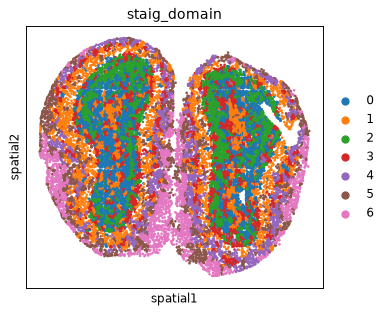

In [5]:
pl.spatial(adata, color="staig_domain", img_key=None, show=False)
plt.show()


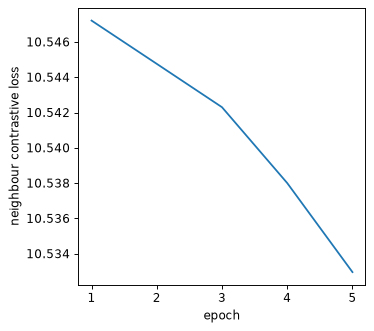

In [6]:
pl.loss_curve(adata)
plt.tight_layout()
plt.show()